In [3]:
# Emotion Recognition from Speech

In [4]:
## Import Libraries
import os
import librosa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

In [5]:
## Dataset Path
data_path = r"C:\Users\palak\OneDrive\Only Palak\Emotion recognition from speech\Audio_Speech_Actors_01-24_16k\Audio_Speech_Actors_01-24_16k"
print("Dataset path:", data_path)

Dataset path: C:\Users\palak\OneDrive\Only Palak\Emotion recognition from speech\Audio_Speech_Actors_01-24_16k\Audio_Speech_Actors_01-24_16k


In [6]:
## Collect audio files_path
files = []   #files = where the audio files are

for actor in os.listdir(data_path):
    actor_path = os.path.join(data_path, actor)

    if os.path.isdir(actor_path):
        for file_name in os.listdir(actor_path):
            if file_name.endswith(".wav"):
                files.append(os.path.join(actor_path, file_name))

print("Total audio files:", len(files))

Total audio files: 1440


In [7]:
## Get the file_name from the full audio path
file_name = os.path.basename(files[0])
print("File name:", file_name)

File name: 03-01-01-01-01-01-01.wav


In [8]:
## Split the file_name into parts
parts = file_name.split("-")
print("Parts of file-name:", parts)

Parts of file-name: ['03', '01', '01', '01', '01', '01', '01.wav']


In [9]:
## Get the emotion code(using index)
emotion_code = parts[2]
print("Emotion code:", emotion_code)

Emotion code: 01


In [10]:
## Create emotion mapping
# Map emotion code to emotion name
emotion_map = {
               "01" : "Neutral",
               "02" : "Calm",
               "03" : "Happy",
               "04" : "Sad",
               "05" : "Angry",
               "06" : "Fearful",
               "07" : "Disgust",
               "08" : "Surprised"
              }
print("emotion :", emotion_map[emotion_code]) #emotion_map = dictionary that converts RAVDESS emotion codes into readable emotion names.

emotion : Neutral


In [11]:
# Create an empty list to store emotion labels

emotions = []  #  emotions = what emotion each audio file represents
# print(emotions)

# Go through each audio file
for file in files:
    file_name = os.path.basename(file)
    # print("File name:", file_name)
    parts = file_name.split("-")
    emotion_code = parts[2]
    emotion = emotion_map[emotion_code]
    emotions.append(emotion)
print("Emotion labels:", len(emotions))
print("Audio files:", len(files))

Emotion labels: 1440
Audio files: 1440


In [12]:
## Check file -> Emotion label
for i in range(5):
    print(os.path.basename(files[i]), "->", emotions[i])

03-01-01-01-01-01-01.wav -> Neutral
03-01-01-01-01-02-01.wav -> Neutral
03-01-01-01-02-01-01.wav -> Neutral
03-01-01-01-02-02-01.wav -> Neutral
03-01-02-01-01-01-01.wav -> Calm


In [13]:
# Select the first audio file
file = files[0]

#Load the audio
y, sr = librosa.load(file, sr=None)

#Display the information
print("Audio file:", os.path.basename(file))
print("Sample rate:", sr)
print("Number of samples:", len(y))

Audio file: 03-01-01-01-01-01-01.wav
Sample rate: 16000
Number of samples: 52853


In [14]:
# Calculate mfcc
mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
print("MFCC shape:", mfcc.shape)

MFCC shape: (13, 104)


In [15]:
# Import the visualization library  
import librosa.display

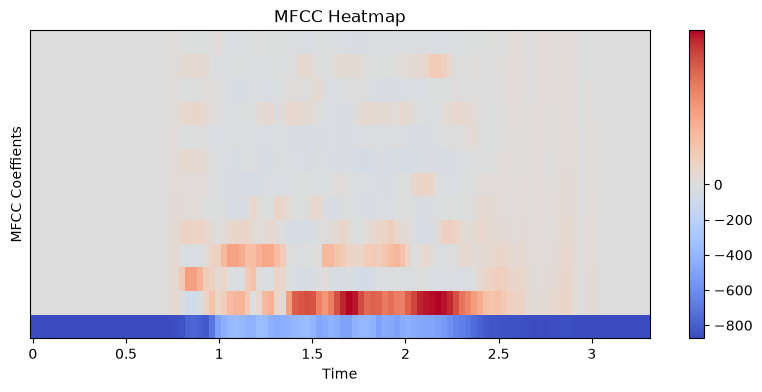

In [16]:
# Plot the mfcc heatmap
plt.figure(figsize=(10,4))

librosa.display.specshow(
                         mfcc, x_axis="time", sr=sr
                        )

plt.colorbar()
plt.title("MFCC Heatmap")
plt.xlabel("Time")
plt.ylabel("MFCC Coeffients")
plt.show()

In [17]:
# Create a fresh list for all MFCC feaatures
features = []

# Process every audio file
for file in files:
    y, sr = librosa.load(file, sr=None)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    features.append(mfcc)

print("Total audio files:", len(files))
print("Total feature entries:", len(features))
print("MFCC entries:", len(features))
print("Emotion labels:", len(emotions))

print("First MFCC shape:", features[0].shape)
print("First emotion label:", emotions[0])

Total audio files: 1440
Total feature entries: 1440
MFCC entries: 1440
Emotion labels: 1440
First MFCC shape: (13, 104)
First emotion label: Neutral


In [18]:
# Find the number of the frames in each MFCC matrix
frame_lengths = [mfcc.shape[1] for mfcc in features]

print("Shortest recording (frames):", min(frame_lengths))
print("Longest recording (frames):", max(frame_lengths))

# Why is this important?
# Suppose the shortest matrix has 90 frames and the longest has 150 frames. 
# We can use that information to decide how to make all matrices the same size.

Shortest recording (frames): 92
Longest recording (frames): 165


In [19]:
# Set the target number of time frames
max_len = 165

# Create a new list for standardized MFCC features
features_fixed = []

# Process each MFCC matrix
for mfcc in features:
    # Add zeros to shorter matrices 
    pad_width = max_len - mfcc.shape[1]

    mfcc_padded = np.pad(
                         mfcc, 
                         pad_width=((0,0), (0, pad_width)),
                         mode = "constant"
                        )

    features_fixed.append(mfcc_padded)

print("Total standardized features:", len(features_fixed))
print("First MFCC shape:", features_fixed[0].shape)
print("Last MFCC shape:", features_fixed[-1].shape)

Total standardized features: 1440
First MFCC shape: (13, 165)
Last MFCC shape: (13, 165)


In [20]:
# Convert MFCC features into a NumPy array
x = np.array(features_fixed)

print("Shape of x:", x.shape)
print("Data type:", x.dtype)
# print(x)

Shape of x: (1440, 13, 165)
Data type: float32


In [21]:
# Display the unique emotion labels
print(set(emotions))

{'Neutral', 'Fearful', 'Happy', 'Disgust', 'Calm', 'Sad', 'Surprised', 'Angry'}


In [22]:
# Map emotion names to numerical labels
label_map = {
             "Neutral": 0,
             "Calm": 1,
             "Happy": 2,
             "Sad": 3,
             "Angry": 4,
             "Fearful": 5,
             "Disgust": 6,
             "Surprised": 7
            }

# Connert emotion names into numbers
y = np.array([label_map[emotion] for emotion in emotions])

print("Shape of y:", y.shape)
print("First 10 labls:", y[:10])

Shape of y: (1440,)
First 10 labls: [0 0 0 0 1 1 1 1 1 1]


In [23]:
# Count recordings for each emotion
for emotion, label in label_map.items():
    print(emotion, ":", np.sum(y == label))

Neutral : 96
Calm : 192
Happy : 192
Sad : 192
Angry : 192
Fearful : 192
Disgust : 192
Surprised : 192


In [24]:
from sklearn.model_selection import train_test_split

In [25]:
# Split the dataset into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
                                                    x, y, test_size=0.2, random_state=42,stratify=y
                                                   )

print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (1152, 13, 165)
Testing features: (288, 13, 165)
Training labels: (1152,)
Testing labels: (288,)


In [26]:
# Add a channel dimension to the MFCC features
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (1152, 13, 165, 1)
Testing data shape: (288, 13, 165, 1)


In [27]:
print("Minimum MFCC value:", x_train.min())
print("Maximum MFCC value:", x_train.max())
print("Mean MFCC value:", x_train.mean())

Minimum MFCC value: -1075.8113
Maximum MFCC value: 237.66052
Mean MFCC value: -30.974064


In [28]:
print("Training emotion classes:", np.unique(y_train))
print("Testing emotion classes:", np.unique(y_test))

Training emotion classes: [0 1 2 3 4 5 6 7]
Testing emotion classes: [0 1 2 3 4 5 6 7]


In [29]:
# Import the CNN components
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [30]:
# Build the CNN model
model = Sequential([
                    Conv2D(32, (3,3), activation="relu", input_shape=(13,165,1)),
                    MaxPooling2D((2,2)),
                    Flatten(),
                    Dense(64, activation="relu"),
                    Dropout(0.3),
                    Dense(8, activation="softmax")
                   ])

c:\Users\palak\OneDrive\Only Palak\Emotion recognition from speech\.mlenv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [31]:
# Compile the CNN model
model.compile(
              optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"]
             )

In [32]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 11, 163, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 5, 81, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12960)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       829,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 830,344 (3.17 MB)

 Trainable params: 830,344 (3.17 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
# Train the CNN model
history = model.fit(
                    x_train, y_train, epochs=20,batch_size=32, validation_split=0.2
                   )

Epoch 1/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.1444 - loss: 24.9001 - val_accuracy: 0.1299 - val_loss: 2.0788
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.1183 - loss: 2.0796 - val_accuracy: 0.1299 - val_loss: 2.0781
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.1336 - loss: 2.0775 - val_accuracy: 0.1299 - val_loss: 2.0773
Epoch 4/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.1336 - loss: 2.0763 - val_accuracy: 0.1299 - val_loss: 2.0765
Epoch 5/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.1336 - loss: 2.0752 - val_accuracy: 0.1299 - val_loss: 2.0759
Epoch 6/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.1336 - loss: 2.0741 - val_accuracy: 0.1299 - val_loss: 2.0752
Epoch 7/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.1151 - loss: 2.0730 - val_accuracy: 0.1299 - val_loss: 2.0747
Epoch 8/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.1151 - loss: 2.0721 - val_accuracy: 0.1126 - 

In [34]:
# Calculate scaling values from training data only
mean_value = x_train.mean()
std_value = x_train.std()

#Standardize training and testing festures
x_train_scaled = (x_train - mean_value) / (std_value + 1e-8)
x_test_scaled = (x_test - mean_value) / (std_value + 1e-8)

print("Training data mean:", x_train_scaled.mean())
print("Training data stadard deviation:", x_train_scaled.std())

Training data mean: 1.6178624e-09


Training data stadard deviation: 1.0000001


In [35]:
# Build a fresh CNN model
model_scaled =  Sequential([
                            Conv2D(32, (3,3), activation="relu", input_shape=(13,165,1)),
                            MaxPooling2D((2,2)),
                            Flatten(),
                            Dense(64, activation="relu"),
                            Dropout(0.3),
                            Dense(8, activation="softmax")
                           ])

In [36]:
# Compile the fresh CNN model
model_scaled.compile(
                     optimizer="adam",
                     loss="sparse_categorical_crossentropy",
                     metrics=["accuracy"]
                    )

In [37]:
# Train the CNN model
history_scaled = model_scaled.fit(
                                  x_train_scaled,
                                  y_train,
                                  epochs=20,
                                  batch_size=32,
                                  validation_split=0.2
                                 )

Epoch 1/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.1878 - loss: 2.0276 - val_accuracy: 0.2035 - val_loss: 1.9600
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.2552 - loss: 1.9202 - val_accuracy: 0.2597 - val_loss: 1.8847
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.2953 - loss: 1.8334 - val_accuracy: 0.2944 - val_loss: 1.7978
Epoch 4/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3138 - loss: 1.7636 - val_accuracy: 0.2987 - val_loss: 1.7557
Epoch 5/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3518 - loss: 1.6792 - val_accuracy: 0.3593 - val_loss: 1.6982
Epoch 6/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.3996 - loss: 1.6018 - val_accuracy: 0.3506 - val_loss: 1.6850
Epoch 7/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.3920 - loss: 1.5771 - val_accuracy: 0.3983 - val_loss: 1.6086
Epoch 8/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.4235 - loss: 1.5067 - val_accuracy: 0.4329 - v

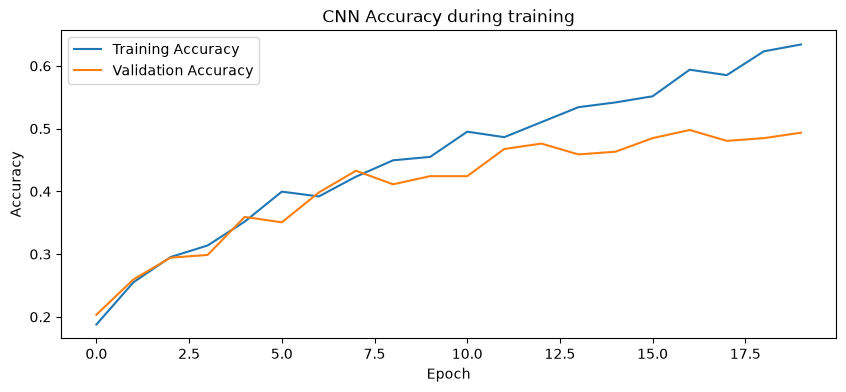

In [38]:
# Visualize CNN accuracy
plt.figure(figsize=(10,4))

plt.plot(history_scaled.history["accuracy"], label="Training Accuracy")
plt.plot(history_scaled.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Accuracy during training")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

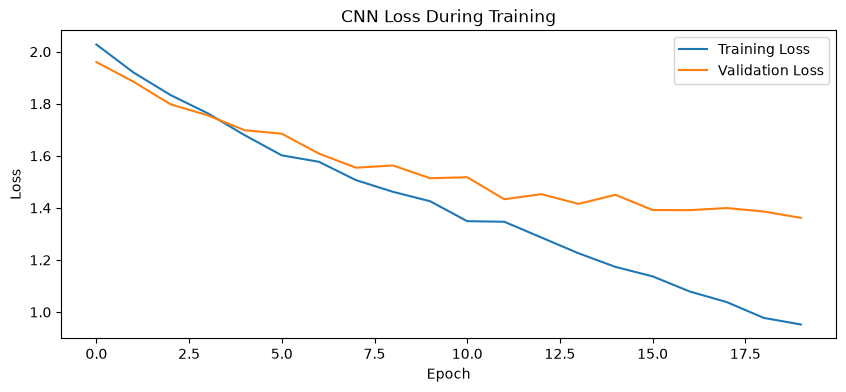

In [39]:
# Loss graph
plt.figure(figsize=(10,4))

plt.plot(history_scaled.history["loss"], label="Training Loss")
plt.plot(history_scaled.history["val_loss"], label="Validation Loss")

plt.title("CNN Loss During Training")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [40]:
from tensorflow.keras.callbacks import EarlyStopping

In [41]:
early_stop = EarlyStopping(
                           monitor="val_loss",
                           patience=3,
                           restore_best_weights=True
                          )

In [42]:
# Building a Fresh CNN Model with Early Stopping
model_early = Sequential([
                          Conv2D(32, (3, 3), activation="relu", input_shape=(13,165,1)),
                          MaxPooling2D((2, 2)),
                          Flatten(),
                          Dense(64, activation="relu"),
                          Dropout(0.3),
                          Dense(8, activation="softmax")
                         ])

In [43]:
# Compile the model 
model_early.compile(
                    optimizer="adam",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"]
                   )

In [44]:
history_early = model_early.fit(
                                x_train_scaled,
                                y_train,
                                epochs=20,
                                batch_size=32,
                                validation_split=0.2,
                                callbacks=[early_stop]
                               )

Epoch 1/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.1705 - loss: 2.0486 - val_accuracy: 0.2381 - val_loss: 1.9725
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.2432 - loss: 1.9356 - val_accuracy: 0.2814 - val_loss: 1.8940
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.2758 - loss: 1.8419 - val_accuracy: 0.3290 - val_loss: 1.7490
Epoch 4/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3138 - loss: 1.7296 - val_accuracy: 0.3636 - val_loss: 1.7134
Epoch 5/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3594 - loss: 1.6771 - val_accuracy: 0.3550 - val_loss: 1.6563
Epoch 6/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3920 - loss: 1.6061 - val_accuracy: 0.3896 - val_loss: 1.6044
Epoch 7/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4235 - loss: 1.5038 - val_accuracy: 0.4199 - val_loss: 1.5740
Epoch 8/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4582 - loss: 1.4425 - val_accuracy: 0.3939 - v

In [45]:
# Check the best epoch
best_loss_epoch = np.argmin(history_early.history["val_loss"]) + 1
best_accuracy_epoch = np.argmax(history_early.history["val_accuracy"]) + 1

print("Best validation loss epoch:", best_loss_epoch)
print("Lowest validation loss:", min(history_early.history["val_loss"]))

print("Best validation accuracy epoch:", best_accuracy_epoch)
print("Highest validation accuracy:", max(history_early.history["val_accuracy"]))

Best validation loss epoch: 15
Lowest validation loss: 1.275178074836731
Best validation accuracy epoch: 15
Highest validation accuracy: 0.5541125535964966


In [46]:
# Evaluating the CNN model on Test Data
test_loss, test_accuracy = model_early.evaluate(
                                                x_test_scaled, y_test, verbose=1
                                               ) 
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Tets Accuracy (%):", test_accuracy * 100)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5347 - loss: 1.3275 
Test Loss: 1.3275208473205566
Test Accuracy: 0.5347222089767456
Tets Accuracy (%): 53.47222089767456


In [47]:
# Evaluate the model
test_loss, test_accuracy = model_early.evaluate(
                                                x_test_scaled, y_test, verbose=1    
                                               )
print("Test Loss:", test_loss)
print("Tets Accuracy:", test_accuracy)
print("Test Accuracy (%)", test_accuracy * 100)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5347 - loss: 1.3275 
Test Loss: 1.3275208473205566
Tets Accuracy: 0.5347222089767456
Test Accuracy (%) 53.47222089767456


In [48]:
from sklearn.metrics import classification_report

emotion_names = [
                 "Neutral", "Calm", "Happy", "Sad", "Angry", "Fearful", "Disgust", "Surprised"
                ]

y_prediction = np.argmax(
                         model_early.predict(x_test_scaled),
                         axis=1
                        )

print(
      classification_report(
                            y_test,
                            y_prediction,
                            labels=list(range(8)),
                            target_names=emotion_names,
                            zero_division=0
                           )
     )

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
              precision    recall  f1-score   support

     Neutral       0.42      0.26      0.32        19
        Calm       0.64      0.66      0.65        38
       Happy       0.48      0.37      0.42        38
         Sad       0.41      0.45      0.43        38
       Angry       0.71      0.74      0.72        39
     Fearful       0.38      0.26      0.31        39
     Disgust       0.53      0.63      0.58        38
   Surprised       0.55      0.77      0.64        39

    accuracy                           0.53       288
   macro avg       0.52      0.52      0.51       288
weighted avg       0.52      0.53      0.52       288



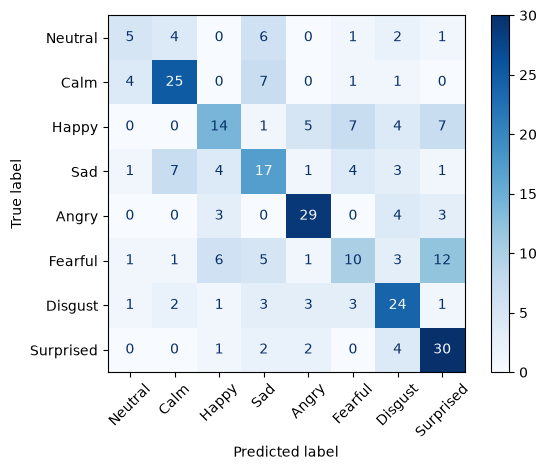

In [49]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_prediction, labels=list(range(8)))

display = ConfusionMatrixDisplay(
                                 confusion_matrix=cm,
                                 display_labels=emotion_names
                                )

display.plot(xticks_rotation=45, cmap="Blues")
plt.tight_layout()
plt.show()

In [50]:
# Prediction Demo

prediction_scores = model_early.predict(
                                        x_test_scaled[i:i+1],
                                        verbose=0
                                       )

predicted_label = np.argmax(prediction_scores)
actual_label = y_test[i]

print("Actual emotion:", emotion_names[actual_label])
print("Predicted emotion:", emotion_names[predicted_label])

Actual emotion: Happy
Predicted emotion: Surprised
